In [1]:
import os
os.environ["PYOPENGL_PLATFORM"] = "osmesa"
os.environ["PYVISTA_OFF_SCREEN"] = "True"
os.environ["PYVISTA_USE_WGL"] = "True"
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '1' #Select the GPU Card
print('Process id: ',os.getpid())

# Importing necessary libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
#from sklearn.ensemble import ExtraTreesClassifier
#from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate
from sklearn.utils.class_weight import compute_class_weight


from sklearn import metrics
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import RocCurveDisplay
import shap

Process id:  3359704


In [2]:
# Load the Excel file
Macula_df = pd.read_excel("./Parameter_ONH.xlsx", engine="openpyxl")  # Specify engine for .xlsx files

# Display the first few rows
print(Macula_df.head(5))
print(Macula_df.columns.tolist())

      ID  OD_fovea  OD_I_S  OD_I_N  OD_I_I  OD_I_T  OD_O_S  OD_O_N  OD_O_I  \
0    N17       335     318     330     361     302     353     268     301   
1    N23       289     343     302     370     321     313     277     327   
2    N33       273     429     385     387     315     327     289     321   
3    N10       508     432     350     403     372     336     268     325   
4  43065       368     288     301     266     305     307     289     291   

   OD_O_T  ...  OS_I_T_Vol  OS_O_S_Vol  OS_O_N_Vol  OS_O_I_Vol  OS_O_T_Vol  \
0     317  ...        0.50        1.79        1.71        1.67        1.51   
1     306  ...        0.51        1.77        1.64        1.72        1.60   
2     323  ...        0.54        1.75        1.56        1.72        1.39   
3     305  ...        0.57        1.81        1.65        1.77        1.52   
4     296  ...        0.48        1.70        1.58        1.54        1.45   

   OS_Macula_volume  OS_Center_thickness  OS_Central_minimum_t

In [3]:
# sns.countplot(data = Macula_df, x='Label')

In [4]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OS_fovea = Macula_df["OS_fovea"]
# # print(OD_fovea)

# data = np.column_stack((Label,OS_fovea))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OS_fovea[index_0]
# sch = OS_fovea[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OS_fovea Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [3]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OD_Central_minimum_thickness = Macula_df["OD_Central_minimum_thickness"]
# # print(OD_fovea)

# data = np.column_stack((Label,OD_Central_minimum_thickness))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OD_Central_minimum_thickness[index_0]
# sch = OD_Central_minimum_thickness[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OD_Central_minimum_thickness Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [6]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OS_I_T = Macula_df["OS_I_T"]
# # print(OD_fovea)

# data = np.column_stack((Label,OS_I_T))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OS_I_T[index_0]
# sch = OS_I_T[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OS_I_T Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [7]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OS_Macula_volume = Macula_df["OS_Macula_volume"]
# # print(OD_fovea)

# data = np.column_stack((Label,OS_Macula_volume))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OS_Macula_volume[index_0]
# sch = OS_Macula_volume[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OS_Macula_volume Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [8]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OS_Central_minimum_thickness = Macula_df["OS_Central_minimum_thickness"]
# # print(OD_fovea)

# data = np.column_stack((Label,OS_Central_minimum_thickness))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OS_Central_minimum_thickness[index_0]
# sch = OS_Central_minimum_thickness[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OS_Central_minimum_thickness Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [9]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OD_fovea = Macula_df["OD_fovea"]
# # print(OD_fovea)

# data = np.column_stack((Label,OD_fovea))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OD_fovea[index_0]
# sch = OD_fovea[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OD_fovea Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [10]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OD_Vol = Macula_df["OD_Vol "]
# # print(OD_fovea)

# data = np.column_stack((Label,OD_Vol))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OD_Vol[index_0]
# sch = OD_Vol[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OD_Vol Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [11]:
# from scipy.stats import mannwhitneyu

# Label = Macula_df["Label"]
# # print(Label)

# OS_Central_maximum_thickness = Macula_df["OS_Central_maximum_thickness"]
# # print(OD_fovea)

# data = np.column_stack((Label,OS_Central_maximum_thickness))
# print(data)

# index_0 = np.where(Label==0)[0]
# # print(index_0)

# index_1 = np.where(Label==1)[0]
# # print(index_1)


# healthy = OS_Central_maximum_thickness[index_0]
# sch = OS_Central_maximum_thickness[index_1]

# plt.figure(figsize=(8, 5))

# plt.boxplot([healthy, sch],
#             labels=['Healthy', 'Sch'],
#             patch_artist=True)

# plt.title("Boxplot of OS_Central_maximum_thickness Values")
# plt.ylabel("Value")

# plt.show()


# stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
# print("Mann–Whitney U test p-value:", pvalue)

In [12]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_fovea", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [13]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [14]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [15]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [16]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [17]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [18]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [19]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [20]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [21]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Vol ", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [22]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [23]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [24]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [25]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [26]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [27]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [28]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [29]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [30]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Macula_volume", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [31]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Center_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [32]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Central_minimum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [33]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Central_maximum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [34]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_fovea", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [35]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [36]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [37]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [38]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [39]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [40]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [41]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [42]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [43]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Vol ", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [44]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [45]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [46]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [47]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [48]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [49]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [50]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [51]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [52]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Macula_volume", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [53]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Center_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [54]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Central_minimum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [55]:
# sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Central_maximum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [4]:
# X = iris_skl.data  # Features
# y = iris_skl.target  # Labels

Macula = np.array(Macula_df)
X = Macula[:,1:-1]  # Features
y = Macula[:,-1]  # Labels

y = np.array(y, dtype=np.uint8)
print(X)
print(y)

[[335 318 330 ... 325 192 381]
 [289 343 302 ... 320 234 381]
 [273 429 385 ... 488 246 564]
 ...
 [257 261 291 ... 298 161 308]
 [324 386 353 ... 309 205 383]
 [353 369 298 ... 446 252 472]]
[0 0 0 0 1 0 0 1 0 1 1 1 1 1 1 1 0 0 1 0 1 1 1 0 0 1 0 0 0 0 1 1 1 0 1 1 0
 1 0 1 1 1 0 1 0 0 1 0 1 0]


In [5]:
param_grid = {
    'n_estimators': [100,200,300,500],
    'max_depth': [None,5,10,20],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4],
    'max_features': ['sqrt','log2']
}

rf = RandomForestClassifier(
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=2
)

grid.fit(X, y)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 20],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300, 500]},
             return_train_score=True, scoring='roc_auc', verbose=2)

In [6]:
print("Best Parameters")
print(grid.best_params_)

print("\nBest CV AUC")
print(grid.best_score_)

Best Parameters
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}

Best CV AUC
0.52


In [56]:
def Normalize(arr):
    # Compute min and max for each column
    col_min = arr.min(axis=0)  # Minimum of each column
    col_max = arr.max(axis=0)  # Maximum of each column
    
    # Avoid division by zero (if all values in a column are the same)
    col_range = col_max - col_min
    col_range[col_range == 0] = 1  # Prevent division by zero
    
    # Normalize using broadcasting
    normalized_arr = (arr - col_min) / col_range

    return normalized_arr

def Oversample(arr,num_samp):
    # Number of rows to sample
    num_samples = num_samp 
    
    # Randomly select row indices
    random_indices = np.random.choice(arr.shape[0], num_samples, replace=True)  # replace=True allows duplicates
    
    # Extract the selected rows
    random_rows = arr[random_indices]
    
    # Append the selected rows to the original array
    new_arr = np.vstack((arr, random_rows))
    
    return new_arr



def train_test_split_custom(X, y):
    X = Normalize(X)
    c_array_new = np.column_stack((X,y))

    # Extract the diagnosis column (last column)
    outcome = c_array_new[:, -1]

    c_array_new_0 = c_array_new[outcome == 0]  # Rows where species is 0
    c_array_new_1 = c_array_new[outcome == 1]  # Rows where species is 1

    np.random.shuffle(c_array_new_0)
    np.random.shuffle(c_array_new_1)

    # train test split
    split_len = int(0.7*len(c_array_new_0))
    c_array_new_0_train = c_array_new_0[0:split_len,:]
    c_array_new_0_test =  c_array_new_0[split_len:,:]

    split_len = int(0.7*len(c_array_new_1))
    c_array_new_1_train = c_array_new_1[0:split_len,:]
    c_array_new_1_test =  c_array_new_1[split_len:,:]


    # print(len(c_array_new_0_train),len(c_array_new_0_test))
    # print(len(c_array_new_1_train),len(c_array_new_1_test))

    # oversample
    if False:
        c_array_new_1_train = Oversample(c_array_new_1_train,len(c_array_new_0_train)-len(c_array_new_1_train))

        print(len(c_array_new_0_train),len(c_array_new_0_test))
        print(len(c_array_new_1_train),len(c_array_new_1_test))

    
    # combine
    train = np.concatenate((c_array_new_0_train,c_array_new_1_train), axis = 0)
    test  = np.concatenate((c_array_new_0_test, c_array_new_1_test), axis = 0)
    np.random.shuffle(train)
    np.random.shuffle(test)

    # split
    X_train = train[:,0:-1]
    y_train = train[:,-1]

    X_test = test[:,0:-1]
    y_test = test[:,-1]

    y_train = y_train.astype(int)
    y_test = y_test.astype(int)

    return X_train, X_test, y_train, y_test

In [59]:
# # grid serach
# param_grid = {
#     'n_estimators': [50, 100, 200],
#     'max_depth': [None, 10, 20],
#     'min_samples_split': [2, 5, 10]
# }

# rf = RandomForestClassifier(random_state=42)

# grid = GridSearchCV(
#     rf,
#     param_grid,
#     cv=5,
#     scoring='f1',
#     n_jobs=-1
# )
# X_train, X_test, y_train, y_test = train_test_split(
#     X,
#     y,
#     test_size=0.2,
#     random_state=42,
#     stratify=y
# )
# grid.fit(X_train, y_train)
# print("Best params:", grid.best_params_)
# print("Best CV F1:", grid.best_score_)

In [57]:
feature_names = ['OD_fovea', 'OD_I_S', 'OD_I_N', 'OD_I_I', 'OD_I_T', 'OD_O_S', 'OD_O_N', 'OD_O_I', 'OD_O_T', 'OD_Vol ', 'OD_I_S_Vol', 'OD_I_N_Vol', 'OD_I_I_Vol', 'OD_I_T_Vol', 'OD_O_S_Vol', 'OD_O_N_Vol', 'OD_O_I_Vol', 'OD_O_T_Vol',
                 'OD_Macula_volume', 'OD_Center_thickness', 'OD_Central_minimum_thickness', 'OD_Central_maximum_thickness', 'OS_fovea', 'OS_I_S', 'OS_I_N', 'OS_I_I',
                 'OS_I_T', 'OS_O_S', 'OS_O_N', 'OS_O_I', 'OS_O_T', 'OS_Vol ', 'OS_I_S_Vol', 'OS_I_N_Vol', 'OS_I_I_Vol', 'OS_I_T_Vol', 'OS_O_S_Vol', 'OS_O_N_Vol', 'OS_O_I_Vol',
                 'OS_O_T_Vol', 'OS_Macula_volume', 'OS_Center_thickness', 'OS_Central_minimum_thickness', 'OS_Central_maximum_thickness']

In [58]:
# def normalize_and_train_test_split(X,y,test_size=0.2,normalizeData=True,UseManulaSplit=False,random_state=42):
#     X = Normalize(X)
#     X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=test_size,random_state=random_state,stratify=y)
#     return X_train, X_test, y_train, y_test

In [60]:
# # Monte carlo
# roc_auc_array=[]
# req_auc = 0.8

# # checkpoint for best auc
# best_auc = 0
# X_train_best, X_test_best, y_train_best, y_test_best = [],[],[],[]

# # Initialize an empty list to store SHAP values for each fold
# shap_values_dict = {}


# # array to save roc and cm
# fpr_tpr_array=[]
# pre_recall_array=[]
# cm_array=[]

# count = 0
# for xx in range(5000):
#     # Split the dataset into training and testing sets
#     X_train, X_test, y_train, y_test = normalize_and_train_test_split(X,y,test_size=0.2 ,normalizeData = True, UseManulaSplit = False)
#     # print(np.shape(X_train),np.shape(y_train), np.shape(X_test),  np.shape(y_test) )

#     # Compute class weights if needed
#     class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
#     class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
#     # class_weight_dict = {0: 1, 1: 3}
    
#     # Initialize the Random Forest Classifier
#     #model = RandomForestClassifier(class_weight=class_weight_dict, n_estimators=100, max_depth=None, random_state=42,min_samples_split=5)
#     model = RandomForestClassifier(class_weight=class_weight_dict, n_estimators=100, random_state=42)

#     # Train the model
#     model.fit(X_train, y_train)
    
#     # Make predictions on the test set
#     y_pred_prob = model.predict_proba(X_test)
    
#     # ROC curve
#     fpr, tpr, ft_thresholds = metrics.roc_curve(y_test, y_pred_prob[:,1])    
#     roc_auc = np.round(metrics.auc(fpr, tpr), 2)
#     # plot_ROC_curve(fpr, tpr,roc_auc)

#     # confusion matrix : Automatic find the best threadshold for cm
#     dist = np.sqrt((1 - tpr)**2 + fpr**2)
#     ix = np.argmin(dist)
#     best_thresh = ft_thresholds[ix]

#     y_pred = (y_pred_prob[:,1] >= best_thresh).astype(int)
#     cm = confusion_matrix(y_test, y_pred)
#     # plot_confusion_matrix(cm)

#     # precision-recall curve
#     prec, rec, pr_thresholds = precision_recall_curve(y_test, y_pred_prob[:,1])
    

#     if roc_auc >= req_auc:
#         print(count, 'roc_auc ',roc_auc)
#         X_train_df = pd.DataFrame(X_train, columns=feature_names) # for reflectivity parameters only
#         # X_train_df = pd.DataFrame(X_train, columns=col_keep[31:-1]) # for VF numbers only

#         #Get shap values
#         explainer = shap.TreeExplainer(model)
#         shap_values = explainer(X_train_df)
#         shap_values_dict[xx] = {'SV':shap_values, 'roc':roc_auc}

#         # save trp fpr, prec recall, cm
#         fpr_tpr_array.append(np.column_stack((fpr, tpr, ft_thresholds)))
#         pre_recall_array.append(np.column_stack((prec, rec)))
        
#         cm_array.append(cm)

#         # append auc to array
#         roc_auc_array.append(roc_auc)

#         # counter update
#         count = count +1

#     if roc_auc>best_auc:
#         X_train_best, X_test_best, y_train_best, y_test_best = np.copy(X_train), np.copy(X_test), np.copy(y_train), np.copy(y_test)
#         best_auc = roc_auc



# roc_auc_array = np.array(roc_auc_array)
# print(np.max(roc_auc_array), np.min(roc_auc_array), 
#           np.average(roc_auc_array), np.std(roc_auc_array))


# print(len(fpr_tpr_array),len(pre_recall_array), len(cm_array))

In [61]:
# n_runs = len(fpr_tpr_array)

# mean_fpr = np.linspace(0, 1, 200)

# tprs = []
# aucs = []   # store AUC for each run

# for run in range(n_runs):

#     fpr = fpr_tpr_array[run][:,0]
#     tpr = fpr_tpr_array[run][:,1]

#     # store AUC per run 
#     aucs.append(metrics.auc(fpr, tpr))

#     # interpolate
#     interp_tpr = np.interp(mean_fpr, fpr, tpr)
#     interp_tpr[0] = 0.0
#     tprs.append(interp_tpr)

# tprs = np.array(tprs)

# # ======================
# # statistics
# # ======================
# mean_tpr = np.mean(tprs, axis=0)
# std_tpr  = np.std(tprs, axis=0)

# # CI 
# ci = 1.96 * std_tpr / np.sqrt(n_runs)

# # AUC stats
# mean_auc = np.mean(aucs)
# std_auc  = np.std(aucs)

# # ======================
# # plot
# # ======================
# plt.plot(mean_fpr, mean_tpr, lw=2,
#          label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})')

# plt.fill_between(mean_fpr,
#                  mean_tpr - ci,
#                  mean_tpr + ci,
#                  alpha=0.3,
#                  label='95% CI')

# plt.plot([0,1], [0,1], 'k--')

# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.legend()
# plt.show()


In [62]:
# n_runs = len(pre_recall_array)

# mean_recall = np.linspace(0, 1, 200)

# precs = []
# auprcs = []   # store AUPRC per run

# for run in range(n_runs):

#     prec = pre_recall_array[run][:,0]
#     rec  = pre_recall_array[run][:,1]

#     # ensure recall increasing
#     prec = prec[::-1]
#     rec  = rec[::-1]

#     # store AUPRC per run (CORRECT)
#     auprcs.append(metrics.auc(rec, prec))

#     # interpolate
#     interp_prec = np.interp(mean_recall, rec, prec)
#     precs.append(interp_prec)


# precs = np.array(precs)

# # ======================
# # statistics
# # ======================
# mean_prec = np.mean(precs, axis=0)
# std_prec  = np.std(precs, axis=0)

# # CI for curve
# ci = 1.96 * std_prec / np.sqrt(n_runs)

# # AUPRC stats
# mean_auprc = np.mean(auprcs)
# std_auprc  = np.std(auprcs)

# # ======================
# # plot
# # ======================
# plt.plot(mean_recall, mean_prec, lw=2,
#          label=f'Mean PR (AUC = {mean_auprc:.3f} ± {std_auprc:.3f})')

# plt.fill_between(mean_recall,
#                  mean_prec - ci,
#                  mean_prec + ci,
#                  alpha=0.3,
#                  label='95% CI')

# plt.xlabel('Recall')
# plt.ylabel('Precision')
# plt.legend()
# plt.grid(False)
# plt.show()


In [63]:
# cms_norm = []

# for cm in cm_array:
#     cm = cm / cm.sum(axis=1, keepdims=True)   # row normalization
#     cms_norm.append(cm)

# cms_norm = np.array(cms_norm)

# mean_cm = cms_norm.mean(axis=0)
# std_cm  = cms_norm.std(axis=0)

In [64]:

# fig, ax = plt.subplots(figsize=(4,4))
# im = ax.imshow(mean_cm, interpolation='nearest',  cmap=plt.cm.Blues)

# ax.figure.colorbar(im, ax=ax)

# # We want to show all ticks...
# classes=['Slow','Fast']
# title =''
# ax.set(xticks=np.arange(cm.shape[1]),
#        yticks=np.arange(cm.shape[0]),
#        xticklabels=classes, yticklabels=classes,
#        title=title,
#        ylabel='True label',
#        xlabel='Predicted label')

# # Rotate the tick labels and set their alignment.
# plt.setp(ax.get_xticklabels(), rotation=45, ha="right",rotation_mode="anchor")

# thresh = mean_cm.max() / 2.
# for i in range(mean_cm.shape[0]):
#     for j in range(mean_cm.shape[1]):
#         text = f"{mean_cm[i,j]:.1f}\n±{std_cm[i,j]:.1f}"
#         ax.text(j, i, text,
#                 ha="center", va="center", color="white" if mean_cm[i, j] > thresh else "black")

# fig.tight_layout()

In [65]:
# def plot_ROC_curve(fpr, tpr, roc_auc, clfname = 'Random Forest', classes=['S','F']):
#     fig = plt.figure(figsize=(6,6))
#     lw=2
#     ax = fig.add_subplot(111)
#     ax.plot(fpr, tpr, color='darkorange',lw=lw, label='ROC curve (AUC = %0.2f)' % roc_auc)
#     ax.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
#     ax.set_xlim([0.0, 1.0])
#     ax.set_ylim([0.0, 1.05])
#     ax.set_xlabel('False Positive Rate',fontsize=20)
#     ax.set_ylabel('True Positive Rate',fontsize=20)
#     # ax.set_title('{} ROC'.format(clfname))
#     ax.legend(loc="lower right",fontsize=20)
#     plt.show()



# def plot_PR_curve(rec, prec,pr_auc):
#     fig = plt.figure(figsize=(6,6))
#     lw=2
#     ax = fig.add_subplot(111)
#     ax.plot(rec, prec, color='darkorange',lw=lw, label='PR curve (AUC = %0.2f)' % pr_auc)
#     ax.set_xlim([0.0, 1.0])
#     ax.set_ylim([0.0, 1.05])
#     ax.set_xlabel('Recall',fontsize=20)
#     ax.set_ylabel('Precision',fontsize=20)
#     # ax.set_title('{} ROC'.format(clfname))
#     ax.legend(loc="lower right",fontsize=20)
#     ax.grid(False)
#     plt.show()
# def plot_decision_curve(y_true_, y_pred_prob_):
   
#     def net_benefit(y_true, y_prob, pt):
#         """
#         Compute Net Benefit for one threshold
#         """
#         y_pred = (y_prob >= pt).astype(int)
   
#         TP = np.sum((y_pred == 1) & (y_true == 1))
#         FP = np.sum((y_pred == 1) & (y_true == 0))
#         N  = len(y_true)
   
#         NB = (TP/N) - (FP/N) * (pt/(1-pt))
#         return NB
   
   
#     def decision_curve(y_true, y_prob, thresholds):
#         NB_model = []
#         for t in thresholds:
#             NB_model.append(net_benefit(y_true, y_prob, t))
#         return np.array(NB_model)



#     # Compute DCA
#     thresholds = np.linspace(0.01, 0.8, 100)
#     NB_model = decision_curve(y_true_, y_pred_prob_, thresholds)

#     prevalence = np.mean(y_true_)

#     NB_all = prevalence - (1-prevalence)*(thresholds/(1-thresholds))
#     NB_none = np.zeros_like(thresholds)

#     # Plot
#     plt.figure(figsize=(6,5))
   
#     plt.plot(thresholds, NB_model, label='Model', linewidth=2)
#     plt.plot(thresholds, NB_all, '--', label='Treat All')
#     plt.plot(thresholds, NB_none, '--', label='Treat None')
   
#     plt.xlabel('Threshold Probability')
#     plt.ylabel('Net Benefit')
#     plt.title('Decision Curve Analysis')
#     # plt.xlim([0.0, 1.0])
#     plt.ylim()
#     plt.legend()
#     plt.grid()
   
#     plt.show()

In [66]:
# ================================
# Hyperparameter Grid
# ================================
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# ================================
# INITIALIZATION
# ================================
best_auc = 0
best_params = None

mean_fpr = np.linspace(0, 1, 100)
mean_recall = np.linspace(0, 1, 100)

tprs = []
aucs = []
accs = []

precisions = []
aps = []

threshold_list = []
best_params_list = []

# ================================
# Monte-Carlo Cross Validation
# ================================
for mci in range(5000):

    # ----------------------------
    # Train/Test Split
    # ----------------------------
    X_train, X_test, y_train, y_test = train_test_split_custom(X, y)

    # ----------------------------
    # Class weights
    # ----------------------------
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )

    class_weight_dict = {
        0: class_weights[0],
        1: class_weights[1]
    }

    # ----------------------------
    # Base Model
    # ----------------------------
    rf = RandomForestClassifier(
        class_weight=class_weight_dict,
        random_state=42
    )

    # ----------------------------
    # Nested Grid Search
    # ----------------------------
    grid = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    best_params_list.append(grid.best_params_)

    # ----------------------------
    # Test Evaluation
    # ----------------------------
    y_pred_prob = best_model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

    roc_auc = auc(fpr, tpr)

    optimal_idx = np.argmax(tpr - fpr)
    optimal_thresh = thresholds[optimal_idx]

    y_pred = (y_pred_prob >= optimal_thresh).astype(int)

    acc = accuracy_score(y_test, y_pred)

    # ROC interpolation
    tpr_interp = np.interp(mean_fpr, fpr, tpr)
    tpr_interp[0] = 0

    tprs.append(tpr_interp)
    aucs.append(roc_auc)
    accs.append(acc)

    # Threshold
    threshold_list.append(optimal_thresh)

    # Precision-Recall
    precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)

    precision_interp = np.interp(
        mean_recall,
        recall[::-1],
        precision[::-1]
    )

    precisions.append(precision_interp)

    aps.append(
        average_precision_score(y_test, y_pred_prob)
    )

    # Best model
    if roc_auc > best_auc:
        best_auc = roc_auc
        best_params = grid.best_params_
        X_train_best = X_train.copy()
        X_test_best = X_test.copy()
        y_train_best = y_train.copy()
        y_test_best = y_test.copy()

# ================================
# POST PROCESSING
# ================================
tprs = np.array(tprs)
precisions = np.array(precisions)
threshold_array = np.array(threshold_list)

mean_tpr = tprs.mean(axis=0)
std_tpr = tprs.std(axis=0)
mean_tpr[-1] = 1

mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

mean_acc = np.mean(accs)
std_acc = np.std(accs)

mean_precision = precisions.mean(axis=0)
std_precision = precisions.std(axis=0)

mean_ap = np.mean(aps)
std_ap = np.std(aps)

print(f"Mean AUC : {mean_auc:.4f} ± {std_auc:.4f}")
print(f"Mean AP  : {mean_ap:.4f} ± {std_ap:.4f}")
print(f"Accuracy : {mean_acc:.4f} ± {std_acc:.4f}")

print("\nBest single split AUC:", best_auc)
print("Best hyperparameters:", best_params)

print("\nMedian Threshold:", np.median(threshold_array))
print("Mean Threshold:", np.mean(threshold_array))

Mean AUC : 0.5935 ± 0.1031
Mean AP  : 0.6830 ± 0.0847
Accuracy : 0.6552 ± 0.0711

Best single split AUC: 0.9730769230769231
Best hyperparameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}

Median Threshold: 0.5710851773687722
Mean Threshold: inf


In [70]:
# ================================
# INITIALIZATION
# ================================
best_auc = 0
best_thresh_global = 0

X_train_best, X_test_best, y_train_best, y_test_best = [], [], [], []

shap_values_dict = {}
auc_macula_list = []

mean_fpr = np.linspace(0, 1, 100)
tprs, aucs, accs = [], [], []

mean_recall = np.linspace(0, 1, 100)
precisions, aps = [], []

threshold_list = []

# ================================
# MAIN LOOP
# ================================
for mci in range(5000):

    # Train-test split (your custom function)
    X_train, X_test, y_train, y_test = train_test_split_custom(X, y)

    # Class weights
    class_weights = compute_class_weight(
        'balanced', classes=np.unique(y_train), y=y_train
    )
    class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

    # Model
    rf_classifier = RandomForestClassifier(
        class_weight=class_weight_dict,
        n_estimators=100,
        random_state=42
    )

    rf_classifier.fit(X_train, y_train)

    # Probabilities
    y_pred_prob = rf_classifier.predict_proba(X_test)[:, 1]

    # ================================
    # ROC
    # ================================
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

    optimal_idx = np.argmax(tpr - fpr)
    optimal_thresh = thresholds[optimal_idx]
    
    y_pred = (y_pred_prob > optimal_thresh).astype(int)

    # Accuracy
    acc = accuracy_score(y_test, y_pred)
    
    roc_auc = auc(fpr, tpr)

    # Interpolation for mean ROC
    tpr_interp = np.interp(mean_fpr, fpr, tpr)
    tpr_interp[0] = 0.0

    # ================================
    # BEST THRESHOLD (ROC distance)
    # ================================
    dist = np.sqrt((1 - tpr)**2 + (fpr)**2)
    ix = np.argmin(dist)
    best_thresh = ft_thresholds[ix]

    # ================================
    # PRECISION-RECALL
    # ================================
    precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
    ap = average_precision_score(y_test, y_pred_prob)

    precision_interp = np.interp(mean_recall, recall[::-1], precision[::-1])

    # ================================
    # STORE ONLY GOOD MODELS
    # ================================
    if roc_auc > 0.8:

        tprs.append(tpr_interp)
        aucs.append(roc_auc)
        auc_macula_list.append(roc_auc)
        accs.append(acc)

        precisions.append(precision_interp)
        aps.append(ap)

        threshold_list.append(best_thresh)

        # ================================
        # SHAP
        # ================================
        X_train_df = pd.DataFrame(X_train, columns=feature_names)
        explainer = shap.TreeExplainer(rf_classifier)
        shap_values = explainer(X_train_df)

        shap_values_dict[mci] = {
            'SV': shap_values,
            'roc': roc_auc
        }

        # ================================
        # BEST MODEL CHECKPOINT
        # ================================
        if roc_auc > best_auc:
            best_auc = roc_auc
            best_thresh_global = best_thresh

            X_train_best = np.copy(X_train)
            X_test_best = np.copy(X_test)
            y_train_best = np.copy(y_train)
            y_test_best = np.copy(y_test)

# ================================
# POST-PROCESSING
# ================================

# Convert to arrays
tprs = np.array(tprs)
precisions = np.array(precisions)
threshold_array = np.array(threshold_list)

# ================================
# MEAN ROC
# ================================
mean_tpr = tprs.mean(axis=0)
std_tpr = tprs.std(axis=0)
mean_tpr[-1] = 1.0

mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

mean_acc = np.mean(accs)
std_acc = np.std(accs)

print(f"Accuracy: {mean_acc:.4f} ± {std_acc:.4f}")

# ================================
# MEAN PR
# ================================
mean_precision = precisions.mean(axis=0)
std_precision = precisions.std(axis=0)

mean_ap = np.mean(aps)
std_ap = np.std(aps)

# ================================
# FINAL THRESHOLD (IMPORTANT)
# ================================
best_threshold_median = np.median(threshold_array)
best_threshold_mean = np.mean(threshold_array)

print("\n========== FINAL RESULTS ==========")
print(f"Best AUC (single split): {best_auc:.4f}")
print(f"Mean AUC: {mean_auc:.4f} ± {std_auc:.4f}")
print(f"Mean AP: {mean_ap:.4f} ± {std_ap:.4f}")

print("\n--- Thresholds ---")
print(f"Median Threshold (RECOMMENDED): {best_threshold_median:.4f}")
print(f"Mean Threshold: {best_threshold_mean:.4f}")
print(f"Std Threshold: {np.std(threshold_array):.4f}")

# # ================================
# # FINAL CONFUSION MATRIX (USING MEDIAN THRESHOLD)
# # ================================
# # Re-train model on BEST SPLIT
# rf_final = RandomForestClassifier(
#     class_weight='balanced',
#     n_estimators=100,
#     random_state=42
# )

# rf_final.fit(X_train_best, y_train_best)

# y_prob_final = rf_final.predict_proba(X_test_best)[:, 1]

# # Apply FINAL threshold
# y_pred_final = (y_prob_final >= best_threshold_median).astype(int)

# cm = confusion_matrix(y_test_best, y_pred_final)

# print("\nConfusion Matrix (Final Threshold):")
# print(cm)

# ================================
# SAVE AUCs (optional)
# ================================
#auc_macula_list = np.array(auc_macula_list)
# np.save("./auc_macula.npy", auc_macula_list)

Accuracy: 0.7576 ± 0.0478

========== FINAL RESULTS ==========
Best AUC (single split): 0.9308
Mean AUC: 0.8393 ± 0.0284
Mean AP: 0.8780 ± 0.0343

--- Thresholds ---
Median Threshold (RECOMMENDED): 0.4900
Mean Threshold: 0.5187
Std Threshold: 0.0756


In [15]:
# # checkpoint for best auc
# best_auc = 0
# X_train_best, X_test_best, y_train_best, y_test_best = [],[],[],[]

# # Initialize an empty list to store SHAP values for each fold
# shap_values_dict = {}
# auc_macula_list   = []

# mean_fpr = np.linspace(0, 1, 100)
# tprs = []
# aucs = []

# mean_recall = np.linspace(0, 1, 100)
# precisions = []
# aps = []

# roc_auc_array = []
# for mci in range(5000):
#     # train test split
#     X_train, X_test, y_train, y_test = train_test_split_custom(X, y)

#     # class weights
#     class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
#     class_weight_dict = {0: class_weights[0], 1: class_weights[1]}


#     # Creating the Random Forest classifier
#     rf_classifier = RandomForestClassifier(class_weight=class_weight_dict, n_estimators=100, random_state=42)

#     # Training the model
#     rf_classifier.fit(X_train, y_train)

#     # Making predictions
#     y_pred_prob = rf_classifier.predict_proba(X_test)
#     #plot_decision_curve(y_test, y_pred_prob[:, 1])

#     fpr, tpr, _ = roc_curve(y_test, y_pred_prob[:, 1])
#     roc_auc = auc(fpr, tpr)
#     #plot_ROC_curve(fpr, tpr, roc_auc, clfname = 'Random Forest', classes=['S','H'])

#     tpr_interp = np.interp(mean_fpr, fpr, tpr)
#     tpr_interp[0] = 0.0

#     y_score = y_pred_prob[:, 1]
    

#     precision, recall, _ = precision_recall_curve(y_test, y_score)
#     #pr_auc = auc(recall, precision)
#     #plot_PR_curve(recall, precision,pr_auc)
#     ap = average_precision_score(y_test, y_score)
    
#     # Interpolate precision at fixed recall points
#     precision_interp = np.interp(mean_recall, recall[::-1], precision[::-1])

#     if roc_auc > 0.8:
#         tprs.append(tpr_interp)
#         aucs.append(roc_auc)
#         auc_macula_list.append(roc_auc)
#         precisions.append(precision_interp)
#         aps.append(ap)
    
#         # SHAP analysis
#         X_train_df = pd.DataFrame(X_train, columns=feature_names) 
#         explainer = shap.TreeExplainer(rf_classifier)
#         shap_values = explainer(X_train_df)

#         shap_values_dict[mci] = {
#         'SV': shap_values,
#         'roc': roc_auc
#         }
        
#         if roc_auc>best_auc:
#             X_train_best, X_test_best, y_train_best, y_test_best = np.copy(X_train), np.copy(X_test), np.copy(y_train), np.copy(y_test)
#             best_auc = roc_auc

# tprs = np.array(tprs)

# mean_tpr = tprs.mean(axis=0)
# std_tpr = tprs.std(axis=0)

# mean_tpr[-1] = 1.0

# mean_auc = np.mean(aucs)
# std_auc = np.std(aucs)

# precisions = np.array(precisions)

# mean_precision = precisions.mean(axis=0)
# std_precision = precisions.std(axis=0)

# mean_ap = np.mean(aps)
# std_ap = np.std(aps)
# auc_macula_list   = np.array(auc_macula_list)
# # np.save("./auc_macula.npy", auc_macula_list)

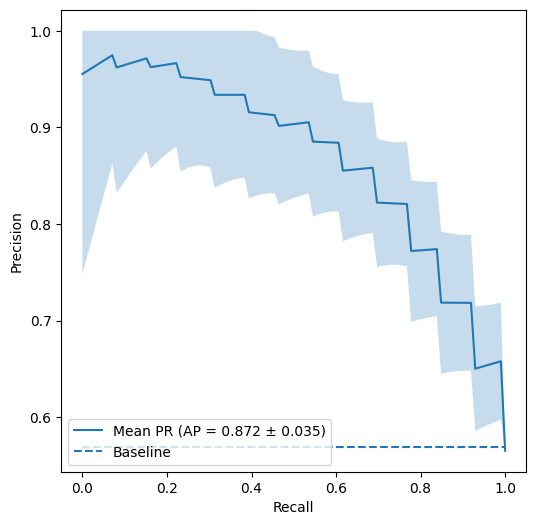

In [70]:
plt.figure(figsize=(6, 6))

plt.plot(
    mean_recall,
    mean_precision,
    label=f"Mean PR (AP = {mean_ap:.3f} ± {std_ap:.3f})"
)

lower = np.maximum(mean_precision - std_precision, 0)
upper = np.minimum(mean_precision + std_precision, 1)

plt.fill_between(
    mean_recall,
    lower,
    upper,
    alpha=0.25
)

# Baseline = positive class prevalence
baseline = np.mean(y)
plt.hlines(
    baseline, 0, 1,
    linestyles="dashed",
    label="Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
# Legend at top-right
plt.legend(loc="lower left")
#plt.tight_layout()
plt.show()


In [71]:
# n_mc = 5000  # Monte Carlo iterations

# plt.figure(figsize=(6, 5))

# plt.plot(
#     mean_recall,
#     mean_precision,
#     label=f"Mean PR (AP = {mean_ap:.3f} ± {std_ap:.3f} SD)"
# )

# # 95% Confidence Interval of the mean
# ci = 1.96 * std_precision / np.sqrt(n_mc)

# lower = np.maximum(mean_precision - ci, 0)
# upper = np.minimum(mean_precision + ci, 1)

# plt.fill_between(
#     mean_recall,
#     lower,
#     upper,
#     alpha=0.25,
#     label="95% CI (MC)"
# )

# # Baseline = positive class prevalence
# baseline = np.mean(y)
# plt.hlines(
#     baseline, 0, 1,
#     linestyles="dashed",
#     label="Baseline"
# )

# plt.xlabel("Recall")
# plt.ylabel("Precision")
# plt.legend(loc="upper right")
# plt.tight_layout()
# plt.show()


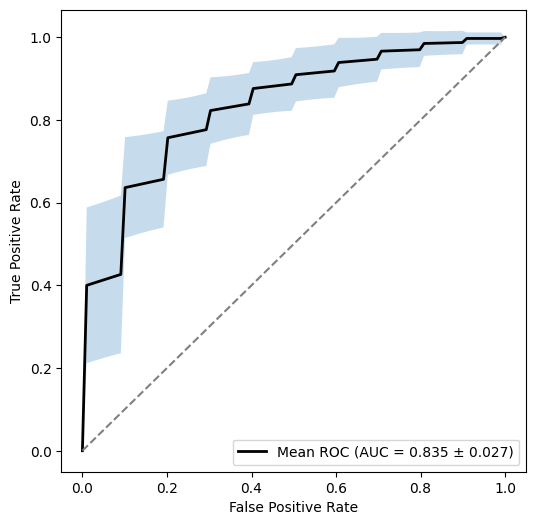

In [73]:

# roc_results = {}
# roc_data = {
#     "mean_fpr": mean_fpr,
#     "mean_tpr": mean_tpr,
#     "std_tpr": std_tpr,
#     "mean_auc": mean_auc,
#     "std_auc": std_auc
# }

# np.save("./ROC_RF.npy", roc_data)
plt.figure(figsize=(6, 6))

plt.plot(
    mean_fpr,
    mean_tpr,
    color='black',
    label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})',
    lw=2
)

plt.fill_between(
    mean_fpr,
    mean_tpr - std_tpr,
    mean_tpr + std_tpr,
    alpha=0.25
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
#plt.title('Mean ROC Curve with Standard Deviation')
plt.legend(loc='lower right')
#plt.grid(True)
plt.show()

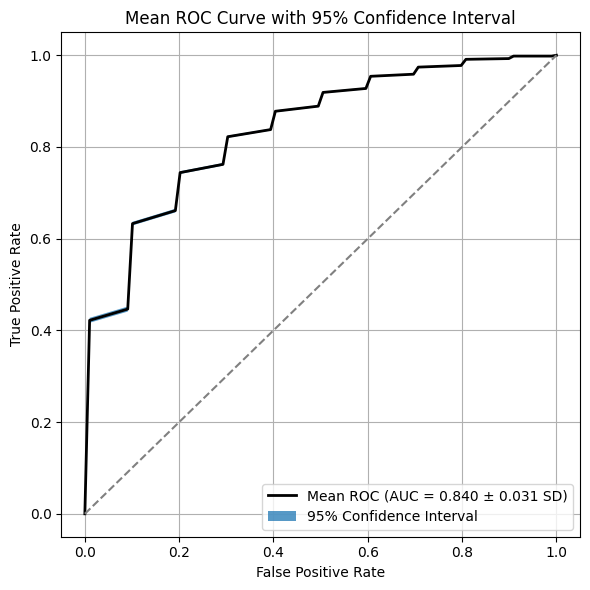

In [72]:
n_mc = 5000

plt.figure(figsize=(6, 6))

# Mean ROC
plt.plot(
    mean_fpr,
    mean_tpr,
    lw=2,
    color="black",
    label=f"Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f} SD)"
)

# 95% CI patch
ci = 1.96 * std_tpr / np.sqrt(n_mc)

tpr_lower = np.maximum(mean_tpr - ci, 0)
tpr_upper = np.minimum(mean_tpr + ci, 1)

plt.fill_between(
    mean_fpr,
    tpr_lower,
    tpr_upper,
    alpha=0.75,
    label="95% Confidence Interval"
)

# Chance line
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Mean ROC Curve with 95% Confidence Interval")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()



(44,)


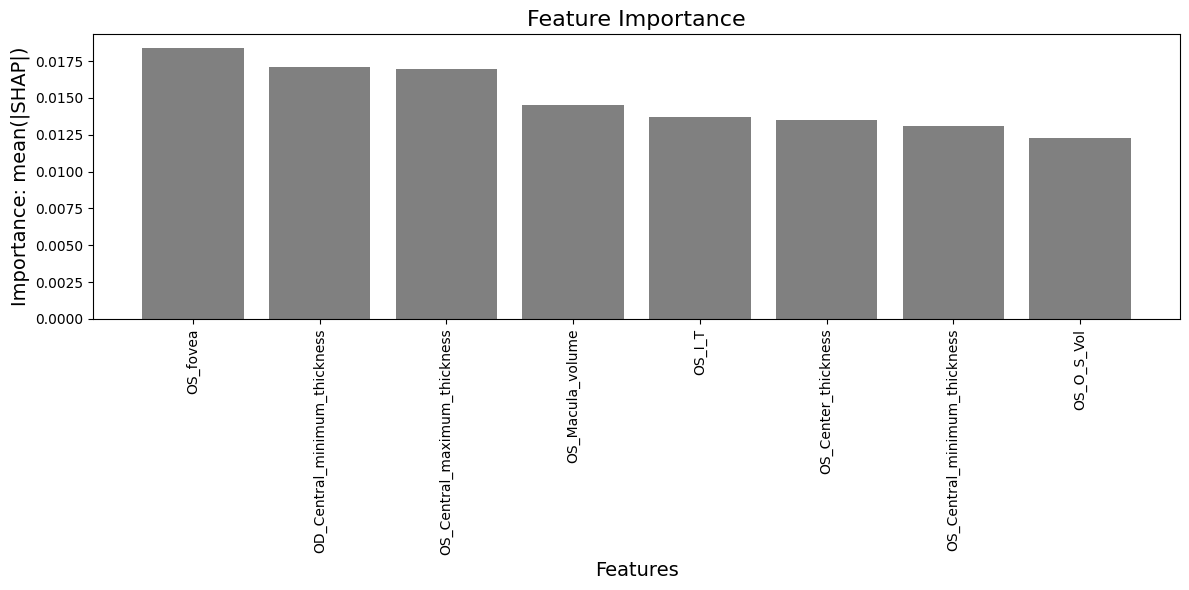

In [74]:
average_shap = []
for key in shap_values_dict:
    tarr = np.array(shap_values_dict[key]['SV'][:,:,0].values)
    average_shap.append(np.mean(np.abs(tarr),axis=0))
    
average_shap = np.array(average_shap)
finalmean = np.mean(average_shap, axis = 0)
print(np.shape(finalmean))

# Step 1: Combine arrays into a 2D array
combined_array = np.column_stack((feature_names, finalmean))

# Step 2: Sort by the second column (numbers) in descending order
sorted_array = combined_array[np.argsort(combined_array[:, 1].astype(float))[::-1]]

# Take top 5 most important features
top8 = sorted_array[:8]



# Plot
plt.figure(figsize=(12, 6), facecolor="none")
# plt.bar(col_keep[:-1], finalmean, color='red')
# plt.bar(sorted_array[:,0],np.round(np.array(sorted_array[:,1],dtype=np.float32), 4), color='gray')
plt.bar(top8[:, 0],np.round(top8[:, 1].astype(float), 4),color='gray')
plt.xlabel('Features', fontsize=14)
plt.ylabel('Importance: mean(|SHAP|)', fontsize=14)
plt.title('Feature Importance', fontsize=16)
plt.xticks(rotation=90, fontsize=10)
plt.tight_layout()
# plt.savefig('./SHAPFeatureImp.png')
plt.show()

In [75]:
# Recompute class weights on best training data
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_best),
    y=y_train_best
)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

# Train RF on best split
rf_best = RandomForestClassifier(
    class_weight=class_weight_dict,
    n_estimators=100,
    random_state=42
)

rf_best.fit(X_train_best, y_train_best)


RandomForestClassifier(class_weight={0: np.float64(1.1666666666666667),
                                     1: np.float64(0.875)},
                       random_state=42)

In [76]:
# Predict probabilities
y_test_prob = rf_best.predict_proba(X_test_best)[:, 1]

# Convert probabilities to class labels
y_test_pred = (y_test_prob >= 0.5).astype(int)

In [77]:
cm = confusion_matrix(y_test_best, y_test_pred)
print(cm)


[[ 4  6]
 [ 0 13]]


<Figure size 600x500 with 0 Axes>

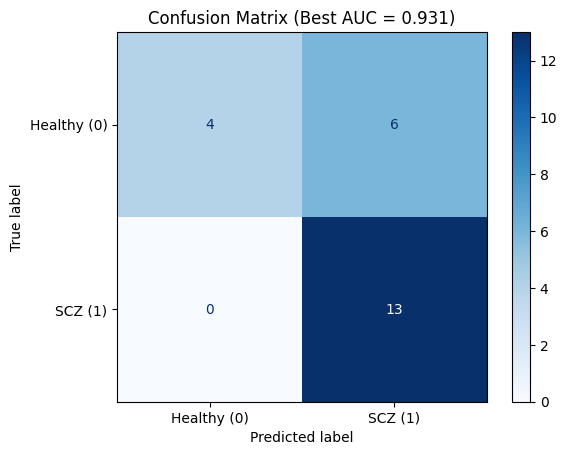

In [78]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy (0)", "SCZ (1)"]
)

plt.figure(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix (Best AUC = {best_auc:.3f})")
plt.show()


In [79]:
# it is better to pass a Panda dataframe to SHAP
X_train_df = pd.DataFrame(X_train, columns=feature_names)

In [79]:
explainer = shap.TreeExplainer(rf_classifier)
shap_values = explainer(X_train_df)

print(np.shape(shap_values.values))

(49, 44, 2)


In [81]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score


def gmm_oct_pipeline(
    df,
    feature_cols,
    label_col=None,
    n_components=2,
    covariance_type='full',
    confidence_threshold=0.7,
    n_bootstrap=200,
    random_state=42,
    grid_step=0.02
):
    """
    Complete GMM pipeline with:
    - Scaling
    - Unsupervised clustering
    - Soft membership probabilities
    - Bootstrap stability analysis
    - Decision-boundary plotting
    - Post-hoc clinical evaluation
    """

    # -----------------------------
    # 1. Feature extraction
    # -----------------------------
    X = df[feature_cols].values
    mask = ~np.isnan(X).any(axis=1)
    X = X[mask]

    y = None
    if label_col is not None:
        y = df.loc[mask, label_col].values

    # -----------------------------
    # 2. Scaling
    # -----------------------------
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # -----------------------------
    # 3. GMM fitting
    # -----------------------------
    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type=covariance_type,
        random_state=random_state
    )

    clusters = gmm.fit_predict(X_scaled)
    probs = gmm.predict_proba(X_scaled)

    confidence = np.max(probs, axis=1)
    uncertain = confidence < confidence_threshold

    # -----------------------------
    # 4. Post-hoc evaluation
    # -----------------------------
    metrics = {}
    if y is not None:
        metrics['ARI'] = adjusted_rand_score(y, clusters)
        metrics['NMI'] = normalized_mutual_info_score(y, clusters)
        metrics['cluster_distribution'] = pd.crosstab(
            clusters, y, normalize='index'
        )

    # -----------------------------
    # 5. Bootstrap stability
    # -----------------------------
    rng = np.random.RandomState(random_state)
    ari_bootstrap = []

    for _ in range(n_bootstrap):
        idx = rng.choice(len(X_scaled), size=len(X_scaled), replace=True)
        X_boot = X_scaled[idx]

        gmm_boot = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            random_state=rng.randint(0, 10000)
        )

        boot_clusters = gmm_boot.fit_predict(X_boot)
        ari = adjusted_rand_score(clusters[idx], boot_clusters)
        ari_bootstrap.append(ari)

    metrics['bootstrap_ARI_mean'] = np.mean(ari_bootstrap)
    metrics['bootstrap_ARI_std'] = np.std(ari_bootstrap)

    # -----------------------------
    # 6. Decision-boundary plotting
    # -----------------------------
    x_min, x_max = X_scaled[:,0].min() - 1, X_scaled[:,0].max() + 1
    y_min, y_max = X_scaled[:,1].min() - 1, X_scaled[:,1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, grid_step),
        np.arange(y_min, y_max, grid_step)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_probs = gmm.predict_proba(grid)
    Z = grid_probs[:, 1].reshape(xx.shape)

    plt.figure(figsize=(7,6))
    contour = plt.contourf(
        xx, yy, Z,
        levels=20,
        cmap='coolwarm',
        alpha=0.75
    )
    plt.colorbar(contour, label='P(Cluster 1)')

    plt.scatter(
        X_scaled[:,0],
        X_scaled[:,1],
        c=clusters,
        cmap='viridis',
        edgecolor='k',
        s=40
    )

    plt.xlabel(f'{feature_cols[0]} (z-score)')
    plt.ylabel(f'{feature_cols[1]} (z-score)')
    plt.title('GMM Soft Decision Boundary with OCT Features')
    plt.show()

    # -----------------------------
    # 7. Return everything
    # -----------------------------
    return {
        'X_scaled': X_scaled,
        'clusters': clusters,
        'probabilities': probs,
        'confidence': confidence,
        'uncertain_mask': uncertain,
        'gmm_model': gmm,
        'metrics': metrics
    }


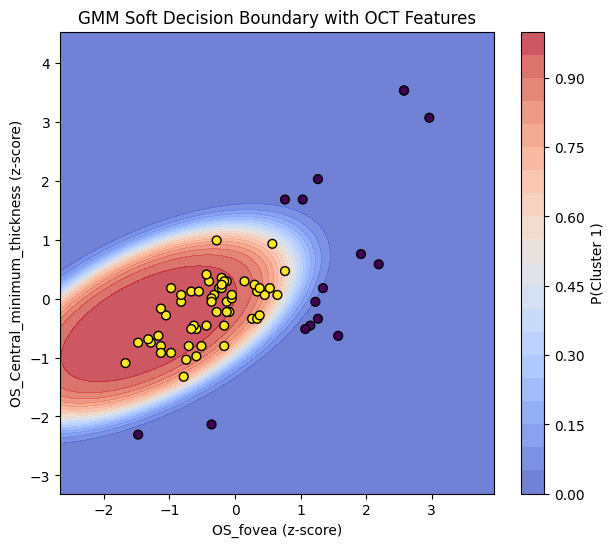

ARI: 0.003846413305450108
Bootstrap ARI mean: 0.6690276197401162
col_0       0       1
row_0                
0      0.1875  0.8125
1      0.5000  0.5000


In [91]:
results = gmm_oct_pipeline(
    df=Macula_df,
    feature_cols=['OS_fovea', 'OS_Central_minimum_thickness'], #'OS_Central_maximum_thickness'],
    label_col='Label',
    n_components=2,
    n_bootstrap=300
)

print("ARI:", results['metrics']['ARI'])
print("Bootstrap ARI mean:", results['metrics']['bootstrap_ARI_mean'])
print(results['metrics']['cluster_distribution'])


In [ ]:
feature_names = ['OD_fovea', 'OD_I_S', 'OD_I_N', 'OD_I_I', 'OD_I_T', 'OD_O_S', 'OD_O_N', 'OD_O_I', 'OD_O_T', 'OD_Vol ', 'OD_I_S_Vol', 'OD_I_N_Vol', 'OD_I_I_Vol', 'OD_I_T_Vol', 'OD_O_S_Vol', 'OD_O_N_Vol', 'OD_O_I_Vol', 'OD_O_T_Vol',
                 'OD_Macula_volume', 'OD_Center_thickness', 'OD_Central_minimum_thickness', 'OD_Central_maximum_thickness', 'OS_fovea', 'OS_I_S', 'OS_I_N', 'OS_I_I',
                 'OS_I_T', 'OS_O_S', 'OS_O_N', 'OS_O_I', 'OS_O_T', 'OS_Vol ', 'OS_I_S_Vol', 'OS_I_N_Vol', 'OS_I_I_Vol', 'OS_I_T_Vol', 'OS_O_S_Vol', 'OS_O_N_Vol', 'OS_O_I_Vol',
                 'OS_O_T_Vol', 'OS_Macula_volume', 'OS_Center_thickness', 'OS_Central_minimum_thickness', 'OS_Central_maximum_thickness']

In [93]:
Macula_df.groupby("cluster")[["OS_fovea", "OS_Central_minimum_thickness"]].mean()


KeyError: 'cluster'

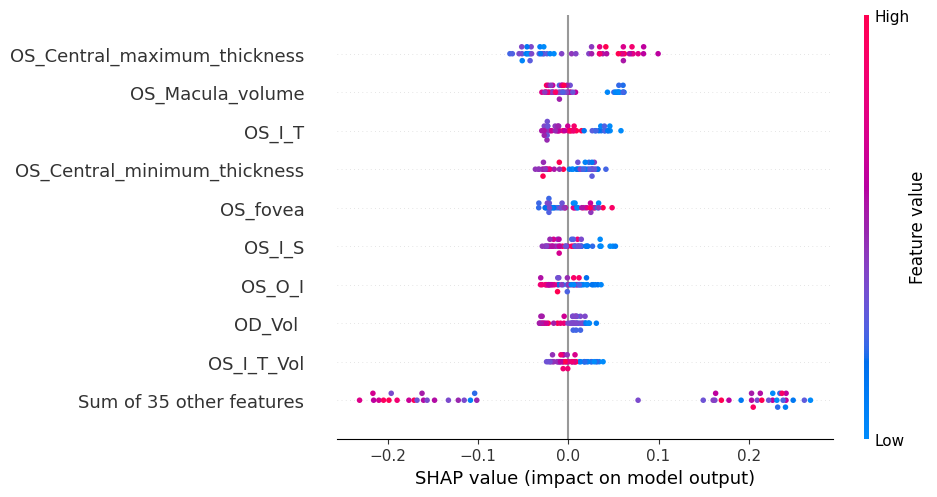

In [80]:
# Beeswarm plot
shap.plots.beeswarm(shap_values[:,:,1])

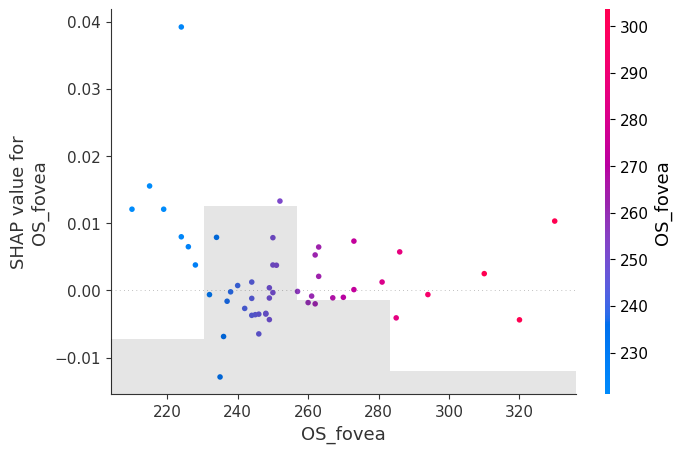

In [81]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_fovea',1], color=shap_values[:,'OS_fovea',1])

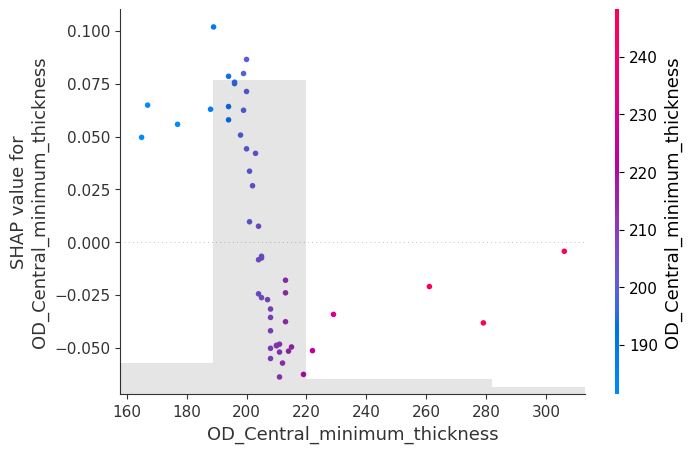

In [82]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OD_Central_minimum_thickness',1], color=shap_values[:,'OD_Central_minimum_thickness',1])

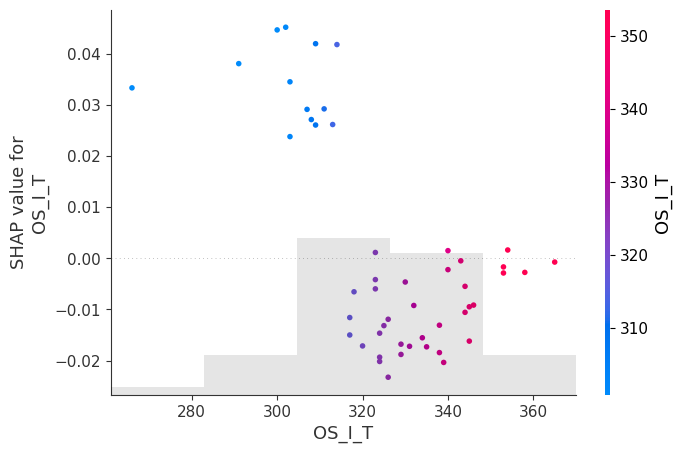

In [83]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_I_T',1], color=shap_values[:,'OS_I_T',1])

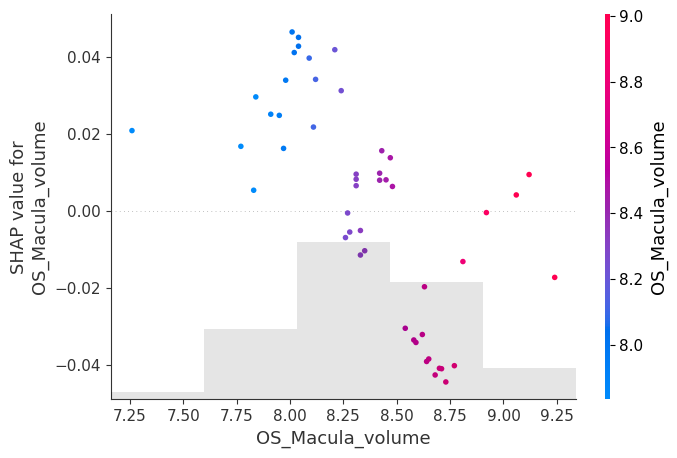

In [84]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_Macula_volume',1], color=shap_values[:,'OS_Macula_volume',1])

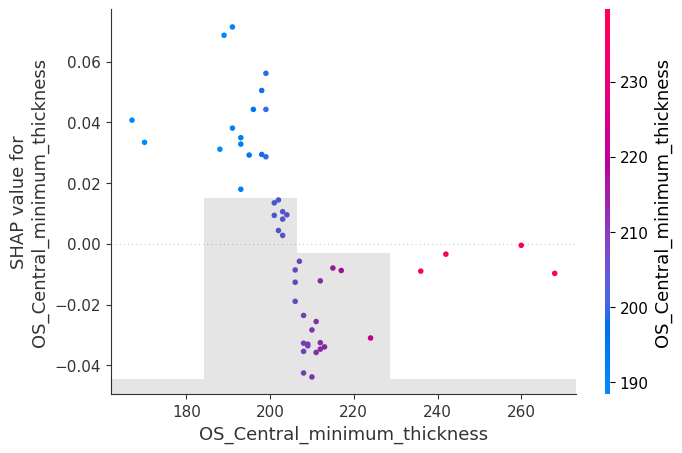

In [85]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_Central_minimum_thickness',1], color=shap_values[:,'OS_Central_minimum_thickness',1])

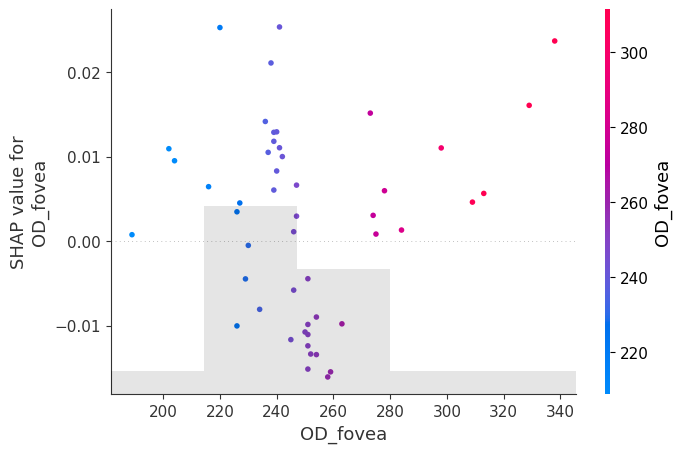

In [86]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OD_fovea',1], color=shap_values[:,'OD_fovea',1])

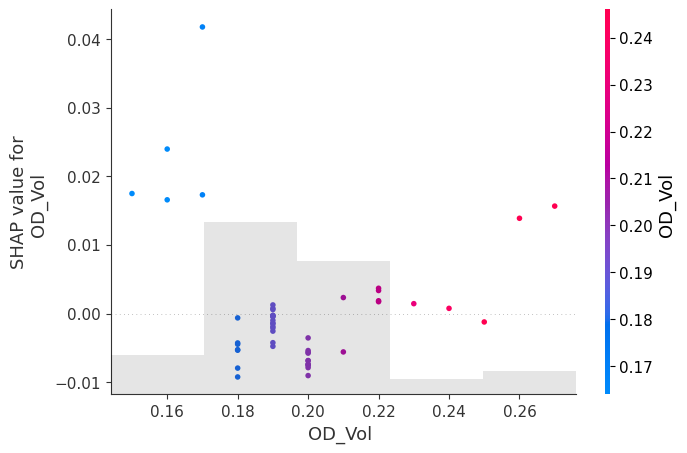

In [87]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OD_Vol ',1], color=shap_values[:,'OD_Vol ',1])

In [88]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OS-T",0], color=shap_values[:,"OS-T",0])

In [89]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OS-I",0], color=shap_values[:,"OS-I",0])

In [90]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OS-N",0], color=shap_values[:,"OS-N",0])

In [91]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-S",0], color=shap_values[:,"OD-S",0])

In [92]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-T",0], color=shap_values[:,"OD-T",0])

In [93]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-I",0], color=shap_values[:,"OD-I",0])

In [94]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-N",0], color=shap_values[:,"OD-N",0])

In [8]:
auc_macula_list = np.load("./auc_macula.npy")
auc_combined_list = np.load("./auc_macula_ONH.npy")
print(auc_macula_list.shape)
print(auc_combined_list.shape)


(120,)
(146,)


In [9]:
from scipy.stats import wilcoxon

n = min(len(auc_macula_list), len(auc_combined_list))

auc_macula_common   = auc_macula_list[:n]
auc_combined_common = auc_combined_list[:n]

stat, p = wilcoxon(auc_macula_common, auc_combined_common)

print(f"Wilcoxon statistic = {stat:.4f}, p-value = {p:.4e}")



Wilcoxon statistic = 3508.0000, p-value = 7.4934e-01
